<a href="https://colab.research.google.com/github/bot18-debug/Deep-Learning/blob/main/cifar10_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Training photos: (50000, 32, 32, 3)
Testing photos: (10000, 32, 32, 3)


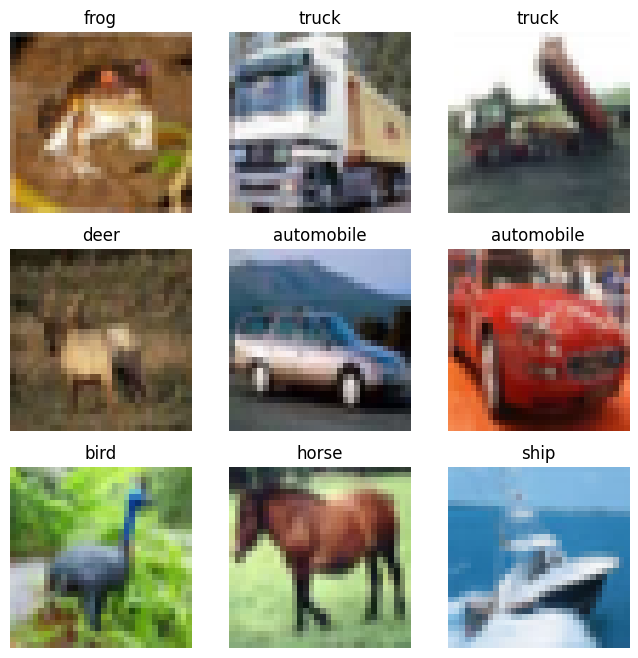

In [14]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from sklearn.metrics import confusion_matrix, classification_report


(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
print("Training photos:", x_train.shape)
print("Testing photos:", x_test.shape)

class_names = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']

plt.figure(figsize=(8,8))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i][0]])
    plt.axis('off')
plt.show()


In [8]:



x_train_norm = x_train / 255.0
x_test_norm = x_test / 255.0


model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(32,32,3)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()


history = model.fit(x_train_norm, y_train, epochs=10,
                     validation_data=(x_test_norm, y_test))

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 3, 3, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │       131,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,719,498 (90.48 MB)

 Trainable params: 131,786 (514.79 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 76s 70ms/step - accuracy: 0.7206 - loss: 0.8551 - val_accuracy: 0.8307 - val_loss: 0.5082
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 34s 44ms/step - accuracy: 0.7924 - loss: 0.6219 - val_accuracy: 0.8457 - val_loss: 0.4574
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 34s 43ms/step - accuracy: 0.8025 - loss: 0.5823 - val_accuracy: 0.8482 - val_loss: 0.4439
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 34s 43ms/step - accuracy: 0.8119 - loss: 0.5571 - val_accuracy: 0.8505 - val_loss: 0.4379
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 45s 49ms/step - accuracy: 0.8145 - loss: 0.5402 - val_accuracy: 0.8560 - val_loss: 0.4287
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 41s 49ms/step - accuracy: 0.8213 - loss: 0.5241 - val_accuracy: 0.8552 - val_loss: 0.4210
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 33s 43ms/step - accuracy: 0.8239 - loss: 0.5101 - val_accuracy: 0.8556 - val_loss: 0.4220
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 33s 42ms/step - accuracy: 0.8287 - loss: 0.5033 - 

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.2509 - loss: 2.0370 - val_accuracy: 0.3295 - val_loss: 1.8573
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 4ms/step - accuracy: 0.3984 - loss: 1.6561 - val_accuracy: 0.4505 - val_loss: 1.5186
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.4699 - loss: 1.4674 - val_accuracy: 0.4649 - val_loss: 1.4862
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.5160 - loss: 1.3495 - val_accuracy: 0.5038 - val_loss: 1.3491
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5521 - loss: 1.2604 - val_accuracy: 0.5696 - val_loss: 1.2141
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.5822 - loss: 1.1826 - val_accuracy: 0.5649 - val_loss: 1.2304
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6065 - loss: 1.1179 - val_accuracy: 0.5947 - val_loss: 1.1579
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.6295 - loss: 1.0586 

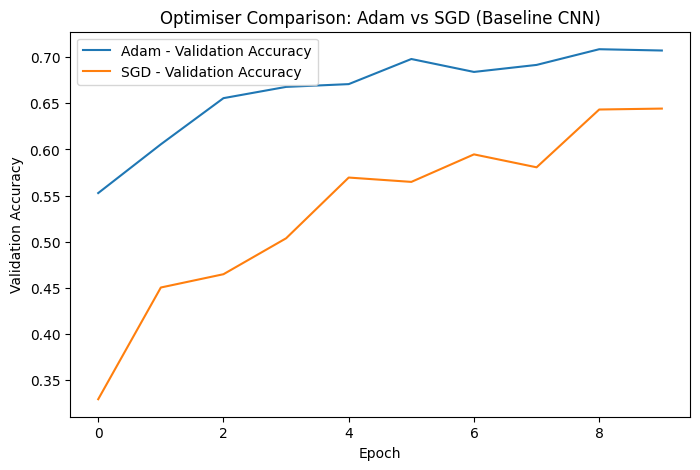

Final Adam val accuracy: 0.7071999907493591
Final SGD val accuracy: 0.6442999839782715


In [16]:
# Experiment: compare optimisers (Adam vs SGD) using the same baseline CNN architecture
model_sgd = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(32,32,3)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model_sgd.compile(optimizer='sgd',
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])

history_sgd = model_sgd.fit(x_train_norm, y_train, epochs=10,
                             validation_data=(x_test_norm, y_test))

# Compare against the original Adam-based baseline (the 'history' variable from Cell 2)
plt.figure(figsize=(8,5))
plt.plot(history.history['val_accuracy'], label='Adam - Validation Accuracy')
plt.plot(history_sgd.history['val_accuracy'], label='SGD - Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.title('Optimiser Comparison: Adam vs SGD (Baseline CNN)')
plt.legend()
plt.show()

print("Final Adam val accuracy:", history.history['val_accuracy'][-1])
print("Final SGD val accuracy:", history_sgd.history['val_accuracy'][-1])

In [7]:

x_train_resnet = preprocess_input(x_train.astype('float32'))
x_test_resnet = preprocess_input(x_test.astype('float32'))


base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(32,32,3))


base_model.trainable = False

model_resnet = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.5),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

model_resnet.compile(optimizer='adam',
                      loss='sparse_categorical_crossentropy',
                      metrics=['accuracy'])

model_resnet.summary()

history_resnet = model_resnet.fit(x_train_resnet, y_train, epochs=10,
                                   validation_data=(x_test_resnet, y_test))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 1, 1, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       131,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,719,498 (90.48 MB)

 Trainable params: 131,786 (514.79 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 55s 22ms/step - accuracy: 0.4452 - loss: 1.6199 - val_accuracy: 0.5836 - val_loss: 1.2155
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.5247 - loss: 1.3549 - val_accuracy: 0.6108 - val_loss: 1.1330
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.5515 - loss: 1.2814 - val_accuracy: 0.6322 - val_loss: 1.0751
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.5685 - loss: 1.2424 - val_accuracy: 0.6305 - val_loss: 1.0614
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 8ms/step - accuracy: 0.5754 - loss: 1.2194 - val_accuracy: 0.6328 - val_loss: 1.0568
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.5804 - loss: 1.2050 - val_accuracy: 0.6396 - val_loss: 1.0329
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - accuracy: 0.5862 - loss: 1.1919 - val_accuracy: 0.6428 - val_loss: 1.0384
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.5870 - loss: 

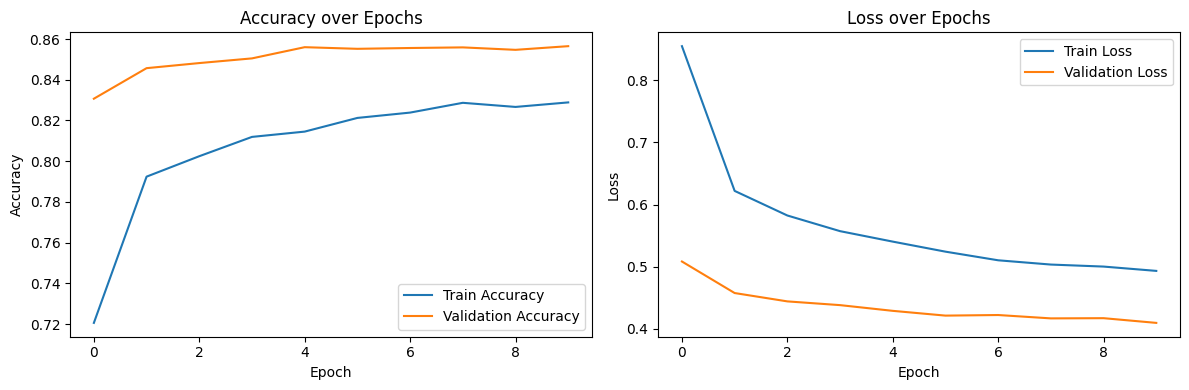

In [10]:

plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(history_resnet.history['accuracy'], label='Train Accuracy')
plt.plot(history_resnet.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Accuracy over Epochs')

plt.subplot(1,2,2)
plt.plot(history_resnet.history['loss'], label='Train Loss')
plt.plot(history_resnet.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss over Epochs')

plt.tight_layout()
plt.show()

157/157 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step


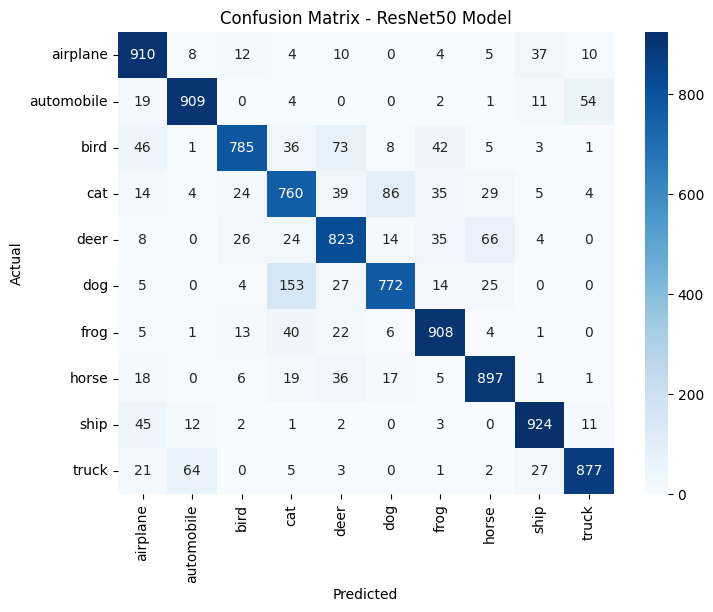

              precision    recall  f1-score   support

    airplane       0.83      0.91      0.87      1000
  automobile       0.91      0.91      0.91      1000
        bird       0.90      0.79      0.84      1000
         cat       0.73      0.76      0.74      1000
        deer       0.80      0.82      0.81      1000
         dog       0.85      0.77      0.81      1000
        frog       0.87      0.91      0.89      1000
       horse       0.87      0.90      0.88      1000
        ship       0.91      0.92      0.92      1000
       truck       0.92      0.88      0.90      1000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000



In [15]:


y_pred_probs = model_resnet.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = y_test.flatten()

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - ResNet50 Model')
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))